In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
print("Libraries imported successfully.")

ImportError: Unable to import required dependency numpy. Please see the traceback for details.

In [ ]:
rfm = pd.read_csv('../data/customer_rfm.csv')
print("RFM dataset shape:", rfm.shape)
print("\nColumns:")
print(rfm.columns.tolist())
rfm.head()


RFM dataset shape: (4338, 4)

Columns:
['CustomerID', 'Recency', 'Frequency', 'Monetary']


,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,2,7,4310.00
2,12348,75,4,1797.24
3,12349,19,1,1757.55
4,12350,310,1,334.40


In [3]:
print("Missing values:")
print(rfm[["Recency", "Frequency", "Monetary"]].isnull().sum())
print("\nDuplicate customer IDs:", rfm['CustomerID'].duplicated().sum())
print("\nSummary statistics:")
display(rfm[["Recency", "Frequency", "Monetary"]].describe().round(2))

Missing values:
Recency      0
Frequency    0
Monetary     0
dtype: int64

Duplicate customer IDs: 0

Summary statistics:


,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,92.54,4.27,2048.69
std,100.01,7.70,8985.23
min,1.00,1.00,3.75
25%,18.00,1.00,306.48
50%,51.00,2.00,668.57
75%,142.00,5.00,1660.60
max,374.00,209.00,280206.02


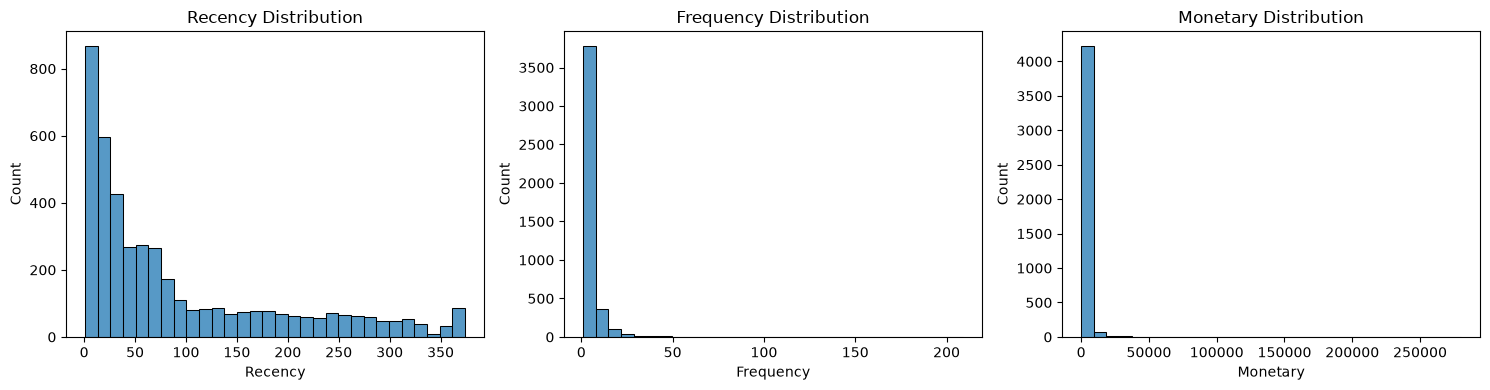

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(rfm['Recency'], bins=30, ax=axes[0])
axes[0].set_title('Recency Distribution')
sns.histplot(rfm['Frequency'], bins=30, ax=axes[1])
axes[1].set_title('Frequency Distribution')
sns.histplot(rfm['Monetary'], bins=30, ax=axes[2])
axes[2].set_title('Monetary Distribution')  
plt.tight_layout()
plt.show()

In [5]:
features = ["Recency", "Frequency", "Monetary"]
print("Non-positive values:")
print((rfm[features] <= 0).sum())
print("\nMissing values:")
print(rfm[features].isnull().sum())


Non-positive values:
Recency      0
Frequency    0
Monetary     0
dtype: int64

Missing values:
Recency      0
Frequency    0
Monetary     0
dtype: int64


In [ ]:
features = ["Recency", "Frequency", "Monetary"]
rfm_ml =rfm.dropna(subset=features).copy()
rfm_ml = rfm_ml[
    (rfm_ml["Recency"] > 0) &
    (rfm_ml["Frequency"] > 0) &
    (rfm_ml["Monetary"] > 0)
].copy()
print("Customer available for clustering:", len(rfm_ml))

SyntaxError: invalid syntax (1653606641.py, line 2)

In [10]:
print("hello boss")

hello boss


In [11]:
features = rfm[["Recency", "Frequency", "Monetary"]]
print("Features ready!")

Features ready!


In [17]:
# Define the features correctly as a flat list
features = ["Recency", "Frequency", "Monetary"]

# Drop rows with missing values in these features
rfm_ml = rfm.dropna(subset=features).copy()

# Keep only customers with positive values
rfm_ml = rfm_ml[
    (rfm_ml["Recency"] > 0) &
    (rfm_ml["Frequency"] > 0) &
    (rfm_ml["Monetary"] > 0)
].copy()

print("Customers available for clustering:", len(rfm_ml))


Customers available for clustering: 4338


In [18]:
X_log = np.log1p(rfm_ml[features])
X_log.head()

,Recency,Frequency,Monetary
0,5.789960,0.693147,11.253955
1,1.098612,2.079442,8.368925
2,4.330733,1.609438,7.494564
3,2.995732,0.693147,7.472245
4,5.739793,0.693147,5.815324


In [19]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_log)

print("Scaled data shape:", X_scaled.shape)

Scaled data shape: (4338, 3)


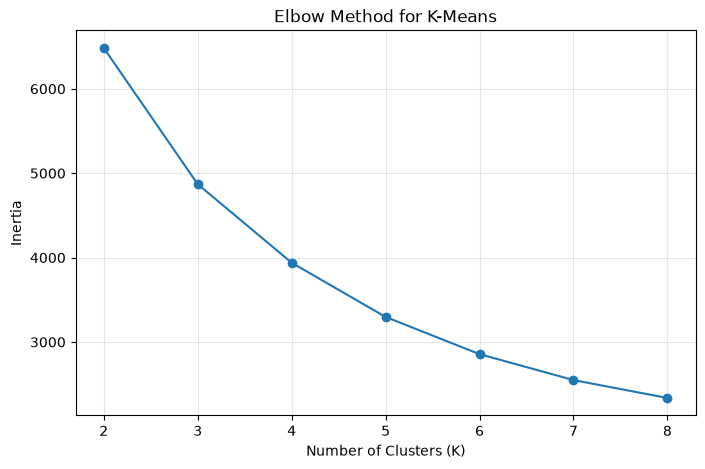

In [20]:
inertias = []
k_values = range(2, 9)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.title("Elbow Method for K-Means")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.show()

In [21]:
silhouette_results = []

for k in range(2, 9):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)

    silhouette_results.append({
        "K": k,
        "Silhouette Score": round(score, 4)
    })

silhouette_df = pd.DataFrame(silhouette_results)

display(
    silhouette_df.sort_values(
        "Silhouette Score",
        ascending=False
    )
)

,K,Silhouette Score
0,2,0.4328
2,4,0.3375
1,3,0.3365
3,5,0.3162
4,6,0.3124
5,7,0.3092
6,8,0.3033


In [22]:
chosen_k = 4  # Elbow aur silhouette results dekh kar change kar sakte ho

kmeans = KMeans(
    n_clusters=chosen_k,
    random_state=42,
    n_init=10
)

rfm_ml["Cluster"] = kmeans.fit_predict(X_scaled)

print("K-Means model trained!")
print("Number of clusters:", chosen_k)

rfm_ml[["CustomerID", "Recency", "Frequency",
        "Monetary", "Cluster"]].head(10)

K-Means model trained!
Number of clusters: 4


,CustomerID,Recency,Frequency,Monetary,Cluster
0,12346,326,1,77183.60,3
1,12347,2,7,4310.00,0
2,12348,75,4,1797.24,3
3,12349,19,1,1757.55,2
4,12350,310,1,334.40,1
5,12352,36,8,2506.04,3
6,12353,204,1,89.00,1
7,12354,232,1,1079.40,1
8,12355,214,1,459.40,1
9,12356,23,3,2811.43,3


In [23]:
cluster_profile = rfm_ml.groupby("Cluster").agg(
    Customer_Count=("CustomerID", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean"),
    Median_Monetary=("Monetary", "median")
).round(2)

cluster_profile

,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary,Median_Monetary
Cluster,,,,,
0,713,12.17,13.75,8088.02,3722.82
1,1622,181.51,1.32,341.00,296.09
2,837,17.70,2.19,557.32,480.31
3,1166,71.64,4.08,1801.78,1345.20


In [24]:
cluster_profile["Customer_Percentage"] = (
    cluster_profile["Customer_Count"] /
    cluster_profile["Customer_Count"].sum() * 100
).round(2)

cluster_profile.sort_values(
    "Avg_Monetary",
    ascending=False
)

,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary,Median_Monetary,Customer_Percentage
Cluster,,,,,,
0,713,12.17,13.75,8088.02,3722.82,16.44
3,1166,71.64,4.08,1801.78,1345.20,26.88
2,837,17.70,2.19,557.32,480.31,19.29
1,1622,181.51,1.32,341.00,296.09,37.39


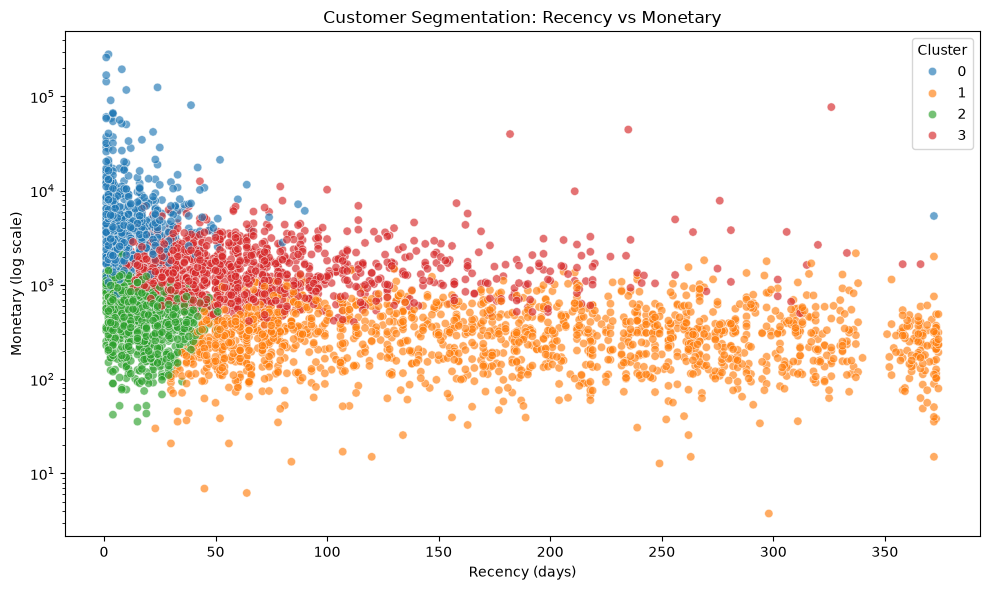

In [25]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rfm_ml,
    x="Recency",
    y="Monetary",
    hue="Cluster",
    palette="tab10",
    alpha=0.65
)

plt.yscale("log")
plt.title("Customer Segmentation: Recency vs Monetary")
plt.xlabel("Recency (days)")
plt.ylabel("Monetary (log scale)")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

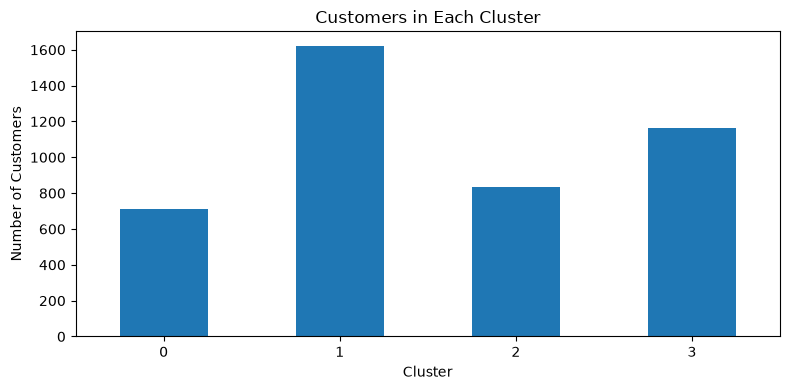

In [26]:
cluster_counts = rfm_ml["Cluster"].value_counts().sort_index()

cluster_counts.plot(
    kind="bar",
    figsize=(8, 4)
)

plt.title("Customers in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [27]:
rfm_ml.to_csv(
    "../data/customer_segments.csv",
    index=False
)

cluster_profile.to_csv(
    "../data/cluster_profile.csv"
)

print("Customer segments saved!")
print("Cluster profile saved!")

Customer segments saved!
Cluster profile saved!


In [28]:
final_silhouette = silhouette_score(X_scaled, rfm_ml["Cluster"])

print("Chosen K:", chosen_k)
print("Silhouette Score:", round(final_silhouette, 4))

Chosen K: 4
Silhouette Score: 0.3375


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("Kernel Connected Successfully!")

ImportError: Unable to import required dependency numpy. Please see the traceback for details.